In [ ]:
from google.colab import files

uploaded = files.upload()



Saving Week 7 - Feature Extraction Practice.pdf to Week 7 - Feature Extraction Practice.pdf


In [ ]:
import pandas as pd
from google.colab import files
from IPython.display import display

# Upload the daily Fitbit CSV.
uploaded = files.upload()
gap_data = pd.read_csv(next(iter(uploaded)))

# Put each person's records in date order.
gap_data["date"] = pd.to_datetime(gap_data["date"]).dt.normalize()
gap_data = gap_data.sort_values(["id", "date"]).reset_index(drop=True)

assert not gap_data.duplicated(["id", "date"]).any(), \
    "Duplicate person/date records need checking first."

# Apply the two cleaning rules we previously used.
gap_data.loc[gap_data["rmssd"] == 0, "rmssd"] = float("nan")

sleep_conflict = (
    (gap_data["minutesAsleep"] == 0)
    & (gap_data["minutesAwake"] == 0)
    & (gap_data["sleep_duration"] > 0)
)
gap_data.loc[sleep_conflict, "minutesAsleep"] = float("nan")

# Check whether neighboring rows are consecutive days for the same person.
consecutive = (
    gap_data["id"].eq(gap_data["id"].shift())
    & gap_data["date"].diff().eq(pd.Timedelta(days=1))
)

results = []

for name, column in [("HRV", "rmssd"), ("Sleep", "minutesAsleep")]:
    missing = gap_data[column].isna()
    new_run = (~consecutive) | missing.ne(missing.shift())
    runs = missing.groupby(new_run.cumsum()).sum()
    gaps = runs[runs > 0]

    results.append({
        "Measurement": name,
        "Missing daily values": int(missing.sum()),
        "1-day gaps": int((gaps == 1).sum()),
        "2–3-day gaps": int(gaps.between(2, 3).sum()),
        "4+ day gaps": int((gaps >= 4).sum()),
        "Longest gap (days)": int(gaps.max()) if len(gaps) else 0
    })

display(pd.DataFrame(results))

Saving daily_fitbit_sema_df_unprocessed(5).csv to daily_fitbit_sema_df_unprocessed(5) (1).csv


,Measurement,Missing daily values,1-day gaps,2–3-day gaps,4+ day gaps,Longest gap (days)
0,HRV,4965,208,88,124,244
1,Sleep,3860,264,121,142,131


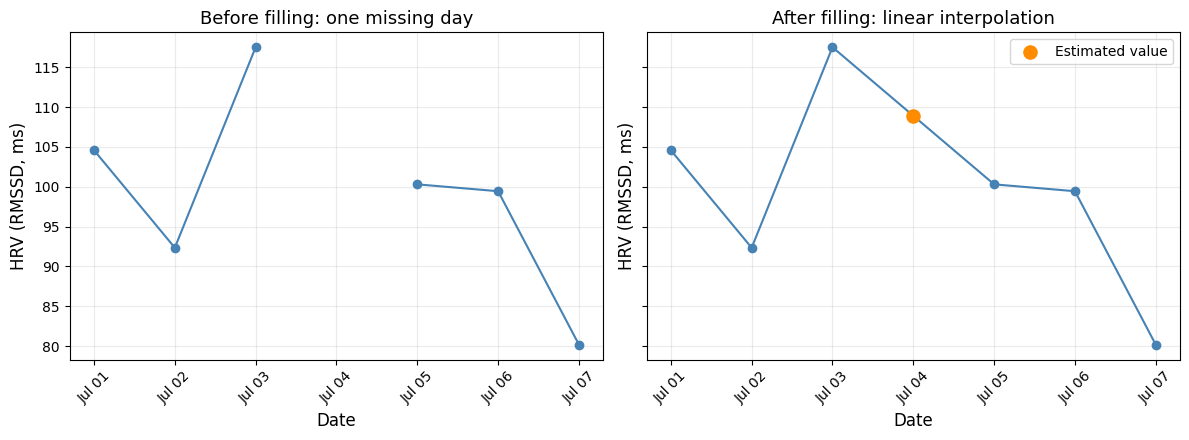

Missing date: 2021-07-04
Previous day: 117.52 ms
Following day: 100.31 ms
Estimated missing value: 108.91 ms


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Work with a copy of the data already loaded.
g = gap_data.sort_values(["id", "date"]).reset_index(drop=True).copy()
people = g.groupby("id")

previous = people["rmssd"].shift(1)
following = people["rmssd"].shift(-1)
previous_date = people["date"].shift(1)
following_date = people["date"].shift(-1)

# Find a missing day with an observed reading on both neighboring days.
suitable_gap = (
    g["rmssd"].isna()
    & previous.notna()
    & following.notna()
    & (g["date"] - previous_date).eq(pd.Timedelta(days=1))
    & (following_date - g["date"]).eq(pd.Timedelta(days=1))
    # Avoid using next Sunday's data to fill Saturday before a Sunday forecast.
    & g["date"].dt.dayofweek.ne(5)
)

if not suitable_gap.any():
    raise ValueError("No suitable one-day HRV gap was found.")

i = suitable_gap[suitable_gap].index[0]
person = g.loc[i, "id"]
gap_date = g.loc[i, "date"]
estimate = (previous.loc[i] + following.loc[i]) / 2

# Show three days on either side of this gap.
example = g.loc[
    g["id"].eq(person)
    & g["date"].between(
        gap_date - pd.Timedelta(days=3),
        gap_date + pd.Timedelta(days=3)
    ),
    ["date", "rmssd"]
].copy()

example["filled_hrv"] = example["rmssd"]
example.loc[example["date"].eq(gap_date), "filled_hrv"] = estimate

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

axes[0].plot(example["date"], example["rmssd"], "o-", color="steelblue")
axes[0].set_title("Before filling: one missing day", fontsize=13)

axes[1].plot(example["date"], example["filled_hrv"], "o-", color="steelblue")
axes[1].scatter(
    gap_date, estimate, color="darkorange", s=90,
    label="Estimated value", zorder=5
)
axes[1].set_title("After filling: linear interpolation", fontsize=13)
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel("HRV (RMSSD, ms)", fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(f"Missing date: {gap_date.date()}")
print(f"Previous day: {previous.loc[i]:.2f} ms")
print(f"Following day: {following.loc[i]:.2f} ms")
print(f"Estimated missing value: {estimate:.2f} ms")

In [ ]:
# Count extra rows for the same participant and date.
daily_repeats = daily_raw.duplicated(
    subset=["id", "date"]
).sum()

# Count extra rows for the same participant, date, and hour.
hourly_repeats = hourly_raw.duplicated(
    subset=["id", "date", "hour"]
).sum()

print("Repeated daily records:", daily_repeats)
print("Repeated hourly records:", hourly_repeats)

Repeated daily records: 0
Repeated hourly records: 70


In [ ]:
# Ignore the saved spreadsheet row number when comparing records.
hourly_check = hourly_raw.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

print(
    "Completely identical extra rows:",
    hourly_check.duplicated().sum()
)

# Make a temporary table with one copy of each identical record.
temporary = hourly_check.drop_duplicates()

# Find repeated hours that still have different values.
needs_review = temporary[
    temporary.duplicated(
        subset=["id", "date", "hour"],
        keep=False
    )
]

print("Rows needing closer inspection:", len(needs_review))
display(needs_review)

Completely identical extra rows: 69
Rows needing closer inspection: 2


,id,date,hour,temperature,badgeType,calories,distance,activityType,bpm,mindfulness_session,...,TENSE/ANXIOUS,TIRED,ENTERTAINMENT,GYM,HOME,HOME_OFFICE,OTHER,OUTDOORS,TRANSIT,WORK/SCHOOL
19315,621e301e67b776a240608a72,2021-08-28,0.0,0.068689,NaN,154.84,88.7,NaN,96.266842,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19316,621e301e67b776a240608a72,2021-08-28,0.0,0.068689,NaN,154.84,88.7,NaN,96.266842,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
different_columns = needs_review.nunique(dropna=False) > 1

display(needs_review.loc[:, different_columns].T)

,19315,19316
minutes_in_default_zone_1,215.0,281.0
minutes_below_default_zone_1,154.0,219.0
minutes_in_default_zone_2,65.0,100.0


In [ ]:
unused_zone_columns = [
    "minutes_in_default_zone_1",
    "minutes_below_default_zone_1",
    "minutes_in_default_zone_2"
]

hourly_clean = (
    hourly_check
    .drop(columns=unused_zone_columns)
    .drop_duplicates()
    .copy()
)

print("Original rows:", len(hourly_raw))
print("Cleaned rows:", len(hourly_clean))
print("Rows removed:", len(hourly_raw) - len(hourly_clean))

print(
    "Remaining repeated person-date-hour records:",
    hourly_clean.duplicated(["id", "date", "hour"]).sum()
)

Original rows: 159508
Cleaned rows: 159438
Rows removed: 70
Remaining repeated person-date-hour records: 0


In [ ]:
print("DAILY MEASUREMENTS")

display(
    daily_raw[["bpm", "resting_hr", "steps", "rmssd", "minutesAsleep"]]
    .describe(percentiles=[0.01, 0.50, 0.99])
    .T[["min", "1%", "50%", "99%", "max"]]
    .round(2)
)

print("HOURLY MEASUREMENTS")

display(
    hourly_clean[["bpm", "steps"]]
    .describe(percentiles=[0.01, 0.50, 0.99])
    .T[["min", "1%", "50%", "99%", "max"]]
    .round(2)
)

DAILY MEASUREMENTS


,min,1%,50%,99%,max
bpm,43.50,58.06,79.79,108.49,154.00
resting_hr,44.12,47.84,66.50,81.10,86.00
steps,0.00,0.00,7420.00,25627.68,43112.00
rmssd,0.00,0.00,34.07,103.48,122.09
minutesAsleep,0.00,80.00,401.00,619.00,1094.00


HOURLY MEASUREMENTS


,min,1%,50%,99%,max
bpm,33.0,47.93,78.5,123.39,192.77
steps,0.0,0.00,116.0,3672.07,9350.00


In [ ]:
print("Daily HRV values equal to zero:",
      (daily_raw["rmssd"] == 0).sum())

print("Daily sleep values equal to zero:",
      (daily_raw["minutesAsleep"] == 0).sum())

zero_readings = (
    (daily_raw["rmssd"] == 0) |
    (daily_raw["minutesAsleep"] == 0)
)

display(
    daily_raw.loc[
        zero_readings,
        ["id", "date", "rmssd", "minutesAsleep", "bpm", "steps"]
    ].head(10)
)

Daily HRV values equal to zero: 30
Daily sleep values equal to zero: 1


,id,date,rmssd,minutesAsleep,bpm,steps
172,621e2ed667b776a24085d8d1,2021-06-06,0.0,261.0,93.743033,995.0
213,621e2ed667b776a24085d8d1,2021-07-17,0.0,261.0,83.655264,1310.0
2018,621e30b267b776a240c5e13f,2021-11-20,0.0,303.0,81.505693,10383.0
2021,621e30b267b776a240c5e13f,2021-11-23,0.0,345.0,76.759664,5262.0
2023,621e30b267b776a240c5e13f,2021-11-25,0.0,262.0,81.167161,9970.0
2024,621e30b267b776a240c5e13f,2021-11-26,0.0,336.0,78.946825,6286.0
2033,621e30b267b776a240c5e13f,2021-12-05,0.0,330.0,88.539876,15912.0
2052,621e30b267b776a240c5e13f,2021-12-24,0.0,178.0,83.377249,10341.0
2060,621e30b267b776a240c5e13f,2022-01-01,0.0,274.0,79.680487,6533.0
2317,621e30e467b776a240e817c7,2021-07-09,0.0,334.0,86.629731,5857.0


In [ ]:
sleep_columns = [
    column for column in daily_raw.columns
    if "sleep" in column.lower()
    or column in ["minutesAwake", "timeInBed"]
]

sleep_to_review = (
    (daily_raw["minutesAsleep"] == 0) |
    (daily_raw["minutesAsleep"] == daily_raw["minutesAsleep"].max())
)

display(
    daily_raw.loc[
        sleep_to_review,
        ["id", "date"] + sleep_columns
    ].T
)

,3836,4363
id,621e332267b776a24092a584,621e339967b776a240e502de
date,2021-05-29,2021-12-05
full_sleep_breathing_rate,18.8,0.0
sleep_points_percentage,0.0,0.0
sleep_duration,74460000.0,34320000.0
minutesToFallAsleep,0.0,0.0
minutesAsleep,1094.0,0.0
minutesAwake,147.0,0.0
sleep_efficiency,94.0,94.0
sleep_deep_ratio,1.968085,0.0


In [ ]:
daily_clean = daily_raw.copy()

# Flag the questionable measurements
daily_clean["hrv_zero_flag"] = daily_clean["rmssd"] == 0

daily_clean["sleep_conflict_flag"] = (
    (daily_clean["minutesAsleep"] == 0) &
    (daily_clean["minutesAwake"] == 0) &
    (daily_clean["sleep_duration"] > 0)
)

# Mark only those measurements as missing
daily_clean.loc[
    daily_clean["hrv_zero_flag"], "rmssd"
] = float("nan")

daily_clean.loc[
    daily_clean["sleep_conflict_flag"], "minutesAsleep"
] = float("nan")

print("HRV values marked missing:",
      daily_clean["hrv_zero_flag"].sum())

print("Sleep values marked missing:",
      daily_clean["sleep_conflict_flag"].sum())

print("Daily rows retained:", len(daily_clean))

HRV values marked missing: 30
Sleep values marked missing: 1
Daily rows retained: 7410


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd

daily_raw = pd.read_csv(
    "/content/daily_fitbit_sema_df_unprocessed(5).csv",
    low_memory=False
)

hourly_raw = pd.read_csv(
    "/content/hourly_fitbit_sema_df_unprocessed(5).csv",
    low_memory=False
)

print("Daily rows:", len(daily_raw))
print("Hourly rows:", len(hourly_raw))

display(
    hourly_raw[
        ["id", "date", "hour", "bpm", "steps", "activityType"]
    ].head(20)
)

Daily rows: 7410
Hourly rows: 159508


,id,date,hour,bpm,steps,activityType
0,621e2e8e67b776a24055b564,2021-05-24,0.0,66.874763,134.0,NaN
1,621e2e8e67b776a24055b564,2021-05-24,1.0,58.711364,0.0,NaN
2,621e2e8e67b776a24055b564,2021-05-24,2.0,55.133495,NaN,NaN
3,621e2e8e67b776a24055b564,2021-05-24,3.0,60.488613,15.0,NaN
4,621e2e8e67b776a24055b564,2021-05-24,4.0,59.110638,0.0,NaN
5,621e2e8e67b776a24055b564,2021-05-24,5.0,57.481481,NaN,NaN
6,621e2e8e67b776a24055b564,2021-05-24,6.0,59.402020,39.0,NaN
7,621e2e8e67b776a24055b564,2021-05-24,7.0,61.217131,0.0,NaN
8,621e2e8e67b776a24055b564,2021-05-24,8.0,60.842478,7.0,NaN
9,621e2e8e67b776a24055b564,2021-05-24,9.0,73.804527,10.0,NaN


In [ ]:
# Check the daily measurements we may use as model inputs.
daily_columns = [
    "bpm",           # Heart rate
    "resting_hr",    # Resting heart rate
    "steps",         # Daily steps
    "rmssd",         # Heart rate variability (HRV)
    "minutesAsleep"  # Sleep duration
]

daily_missing = pd.DataFrame({
    "Missing rows": daily_raw[daily_columns].isna().sum(),
    "Missing (%)": (
        daily_raw[daily_columns].isna().mean() * 100
    ).round(1)
})

print("DAILY DATA")
display(daily_missing)

# Check the hourly measurements.
hourly_columns = ["bpm", "steps"]

hourly_missing = pd.DataFrame({
    "Missing rows": hourly_raw[hourly_columns].isna().sum(),
    "Missing (%)": (
        hourly_raw[hourly_columns].isna().mean() * 100
    ).round(1)
})

print("HOURLY DATA")
display(hourly_missing)

DAILY DATA


,Missing rows,Missing (%)
bpm,2606,35.2
resting_hr,2988,40.3
steps,2633,35.5
rmssd,4935,66.6
minutesAsleep,3859,52.1


HOURLY DATA


,Missing rows,Missing (%)
bpm,63389,39.7
steps,66375,41.6


In [ ]:
coverage = daily_clean.groupby("id").agg(
    days_listed=("date", "nunique"),
    heart_rate_days=("bpm", "count"),
    steps_days=("steps", "count"),
    resting_hr_days=("resting_hr", "count"),
    hrv_days=("rmssd", "count"),
    sleep_days=("minutesAsleep", "count")
)

print("Number of participants:", len(coverage))

print("10 participants with the fewest days containing step data:")
display(coverage.sort_values("steps_days").head(10))

print("Summary across all participants:")
display(
    coverage.describe()
    .loc[["min", "50%", "max"]]
    .round(1)
)

Number of participants: 71
10 participants with the fewest days containing step data:


,days_listed,heart_rate_days,steps_days,resting_hr_days,hrv_days,sleep_days
id,,,,,,
621e30e267b776a240e5bf90,108,1,1,1,0,0
621e333567b776a240a0c217,85,7,7,6,0,1
621e2ef567b776a24099f889,100,36,8,3,0,1
621e328667b776a240281372,132,11,11,10,6,6
621e34ec67b776a240d60873,134,18,18,17,9,10
621e2f5767b776a240d8f9d6,72,26,26,23,0,22
621e309267b776a240ae1cdb,77,27,27,25,0,17
621e332267b776a24092a584,134,29,29,29,15,21
621e32d967b776a240627414,162,32,32,29,2,17


Summary across all participants:


,days_listed,heart_rate_days,steps_days,resting_hr_days,hrv_days,sleep_days
min,64.0,1.0,1.0,1.0,0.0,0.0
50%,88.0,64.0,64.0,64.0,32.0,55.0
max,244.0,243.0,243.0,238.0,206.0,220.0


In [ ]:
coverage = daily_clean.groupby("id").agg(
    days_listed=("date", "nunique"),
    heart_rate_days=("bpm", "count"),
    steps_days=("steps", "count"),
    resting_hr_days=("resting_hr", "count"),
    hrv_days=("rmssd", "count"),
    sleep_days=("minutesAsleep", "count")
)

print("Number of participants:", len(coverage))

print("10 participants with the fewest days of step data:")
display(coverage.sort_values("steps_days").head(10))

print("Summary across all participants:")
display(
    coverage.describe()
    .loc[["min", "50%", "max"]]
    .round(1)
)

Number of participants: 71
10 participants with the fewest days of step data:


,days_listed,heart_rate_days,steps_days,resting_hr_days,hrv_days,sleep_days
id,,,,,,
621e30e267b776a240e5bf90,108,1,1,1,0,0
621e333567b776a240a0c217,85,7,7,6,0,1
621e2ef567b776a24099f889,100,36,8,3,0,1
621e328667b776a240281372,132,11,11,10,6,6
621e34ec67b776a240d60873,134,18,18,17,9,10
621e2f5767b776a240d8f9d6,72,26,26,23,0,22
621e309267b776a240ae1cdb,77,27,27,25,0,17
621e332267b776a24092a584,134,29,29,29,15,21
621e32d967b776a240627414,162,32,32,29,2,17


Summary across all participants:


,days_listed,heart_rate_days,steps_days,resting_hr_days,hrv_days,sleep_days
min,64.0,1.0,1.0,1.0,0.0,0.0
50%,88.0,64.0,64.0,64.0,32.0,55.0
max,244.0,243.0,243.0,238.0,206.0,220.0


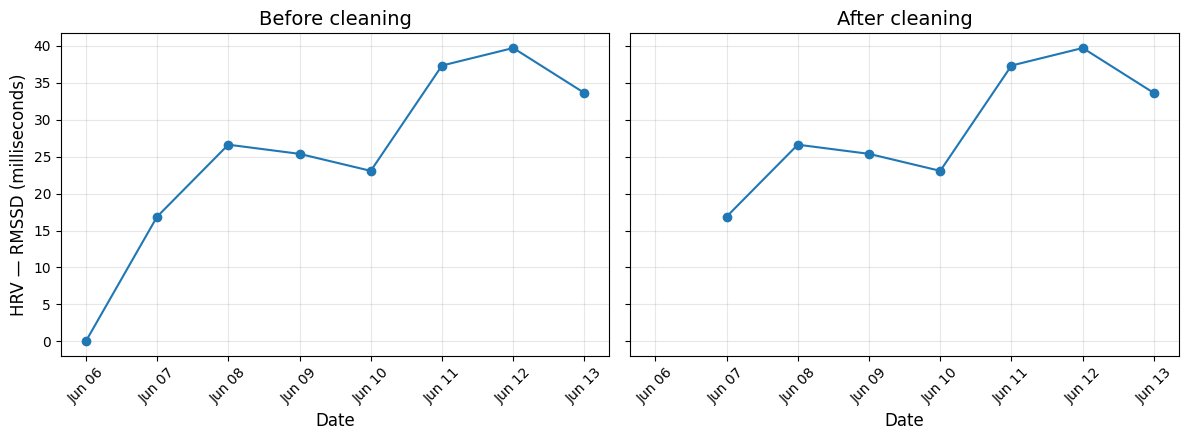

Participant: 621e2ed667b776a24085d8d1


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Prepare dates in plotting copies
raw_plot = daily_raw.copy()
clean_plot = daily_clean.copy()

raw_plot["date"] = pd.to_datetime(raw_plot["date"])
clean_plot["date"] = pd.to_datetime(clean_plot["date"])

# Choose an example with a zero HRV reading
example = raw_plot.loc[raw_plot["rmssd"] == 0].iloc[0]
person_id = example["id"]

# Show one week before and after that reading
dates = pd.date_range(
    example["date"] - pd.Timedelta(days=7),
    example["date"] + pd.Timedelta(days=7)
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), sharex=True, sharey=True
)

for ax, data, title in zip(
    axes,
    [raw_plot, clean_plot],
    ["Before cleaning", "After cleaning"]
):
    values = (
        data.loc[data["id"] == person_id]
        .set_index("date")["rmssd"]
        .reindex(dates)
    )

    ax.plot(values.index, values, marker="o")
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Date", fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("HRV — RMSSD (milliseconds)", fontsize=12)

plt.tight_layout()
plt.show()

print("Participant:", person_id)

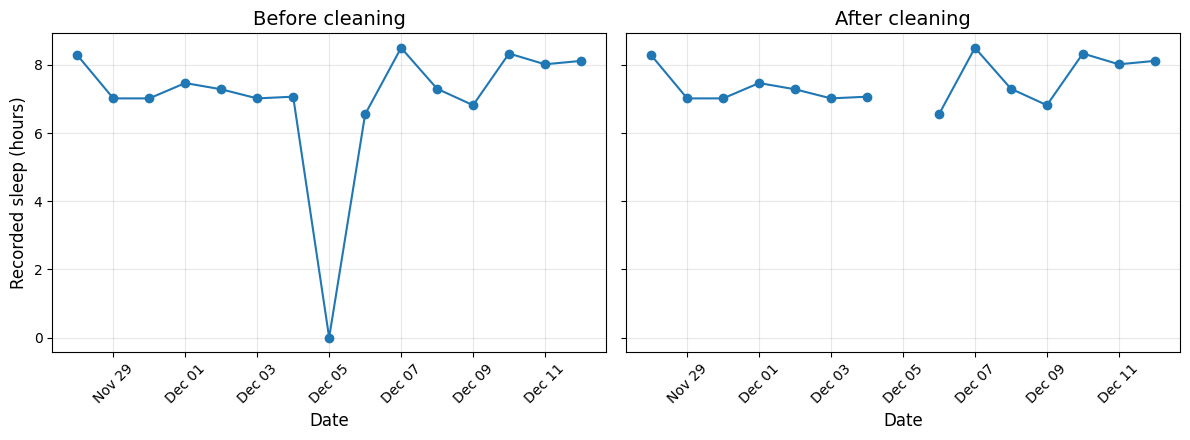

Participant: 621e339967b776a240e502de


In [ ]:
# Save the HRV figure we just made
fig.savefig(
    "/content/HRV_before_after.png",
    dpi=300, bbox_inches="tight"
)

# Find the record with zero minutes asleep
sleep_example = raw_plot.loc[
    raw_plot["minutesAsleep"] == 0
].iloc[0]

sleep_person = sleep_example["id"]

sleep_dates = pd.date_range(
    sleep_example["date"] - pd.Timedelta(days=7),
    sleep_example["date"] + pd.Timedelta(days=7)
)

fig_sleep, sleep_axes = plt.subplots(
    1, 2, figsize=(12, 4.5), sharex=True, sharey=True
)

for ax, data, title in zip(
    sleep_axes,
    [raw_plot, clean_plot],
    ["Before cleaning", "After cleaning"]
):
    values = (
        data.loc[data["id"] == sleep_person]
        .set_index("date")["minutesAsleep"]
        .reindex(sleep_dates)
        / 60
    )

    ax.plot(values.index, values, marker="o")
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Date", fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

sleep_axes[0].set_ylabel("Recorded sleep (hours)", fontsize=12)

fig_sleep.tight_layout()
fig_sleep.savefig(
    "/content/Sleep_before_after.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Participant:", sleep_person)

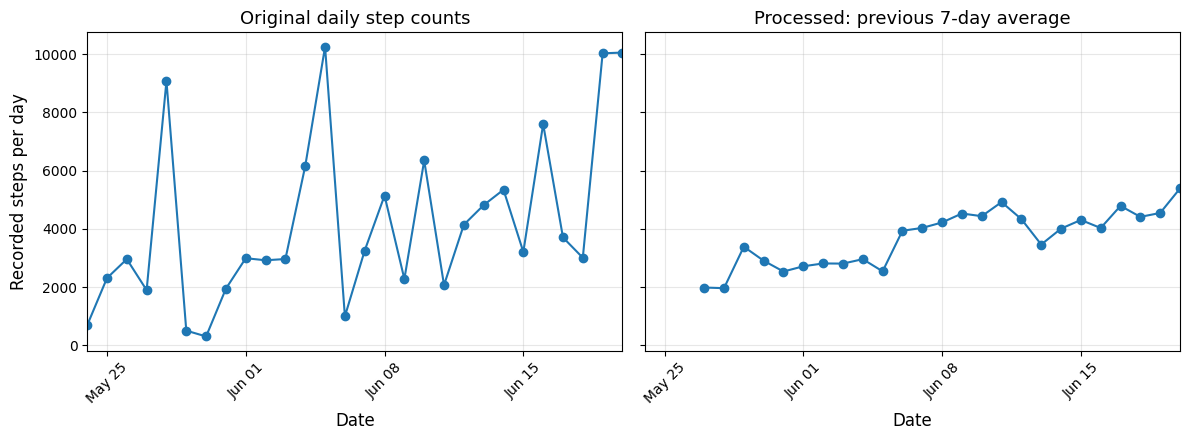

Participant: 621e2ed667b776a24085d8d1


In [ ]:
# Use the same participant as our HRV example
steps = (
    clean_plot.loc[clean_plot["id"] == person_id]
    .set_index("date")["steps"]
    .sort_index()
)

# Include missing calendar days as gaps
calendar_days = pd.date_range(
    steps.index.min(), steps.index.max(), freq="D"
)
steps = steps.reindex(calendar_days)

# Average the previous 7 days, excluding the current day
past_week_mean = steps.rolling(
    "7D", closed="left", min_periods=3
).mean()

# Display 28 days starting with the first recorded step value
start = steps.first_valid_index()
end = start + pd.Timedelta(days=27)

fig_steps, steps_axes = plt.subplots(
    1, 2, figsize=(12, 4.5), sharex=True, sharey=True
)

for ax, values, title in zip(
    steps_axes,
    [steps, past_week_mean],
    ["Original daily step counts", "Processed: previous 7-day average"]
):
    sample = values.loc[start:end]

    ax.plot(sample.index, sample, marker="o")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Date", fontsize=12)
    ax.set_xlim(start, end)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

steps_axes[0].set_ylabel("Recorded steps per day", fontsize=12)

fig_steps.tight_layout()
fig_steps.savefig(
    "/content/Steps_previous_week_mean.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Participant:", person_id)

In [ ]:
# Work with a copy of our cleaned hourly data
hourly_labels = hourly_clean.copy()
hourly_labels["date"] = pd.to_datetime(hourly_labels["date"])

# Keep windows from 6–7 a.m. through 9–10 p.m.
hourly_labels = hourly_labels[
    hourly_labels["hour"].between(6, 21)
].copy()

# Identify hours with a recorded activity start
activity_text = (
    hourly_labels["activityType"].fillna("").astype(str).str.strip()
)
has_start = ~activity_text.isin(["", "[]"])

# Check whether both heart rate and step records are available
has_measurements = (
    hourly_labels["bpm"].notna()
    & hourly_labels["steps"].notna()
)

# Keep recorded starts, plus other hours with both measurements
keep = has_start | has_measurements

hourly_labels["activity_start"] = has_start.astype(int)

print("Hours excluded for insufficient records:", (~keep).sum())

hourly_labels = hourly_labels.loc[keep].copy()

print("Hours retained:", len(hourly_labels))
print("\nOutcome counts:")
print(hourly_labels["activity_start"].value_counts().sort_index())

# Show three examples from each outcome
display(
    hourly_labels.groupby("activity_start").head(3)[
        ["id", "date", "hour", "activityType", "activity_start"]
    ]
)

Hours excluded for insufficient records: 41627
Hours retained: 64466

Outcome counts:
activity_start
0    60875
1     3591
Name: count, dtype: int64


,id,date,hour,activityType,activity_start
6,621e2e8e67b776a24055b564,2021-05-24,6.0,NaN,0
7,621e2e8e67b776a24055b564,2021-05-24,7.0,NaN,0
8,621e2e8e67b776a24055b564,2021-05-24,8.0,NaN,0
10,621e2e8e67b776a24055b564,2021-05-24,10.0,['Walk'],1
17,621e2e8e67b776a24055b564,2021-05-24,17.0,['Walk'],1
33,621e2e8e67b776a24055b564,2021-05-25,9.0,['Walk'],1


In [ ]:
# Prepare the cleaned daily measurements
daily_history = daily_clean.copy()
daily_history["date"] = pd.to_datetime(daily_history["date"])
daily_history["sleep_hours"] = daily_history["minutesAsleep"] / 60

# Start the feature table with our hourly outcomes
feature_data = hourly_labels[
    ["id", "date", "hour", "activity_start"]
].copy()

feature_data["hour"] = feature_data["hour"].astype(int)

# Monday = 0, ..., Sunday = 6
feature_data["weekday"] = feature_data["date"].dt.dayofweek

# Find the Sunday when each week's plan would be created
feature_data["plan_date"] = (
    feature_data["date"]
    - pd.to_timedelta(
        (feature_data["weekday"] + 1) % 7, unit="D"
    )
)

# Original measurement column -> new feature name
feature_names = {
    "steps": "past_mean_steps",
    "bpm": "past_mean_hr",
    "resting_hr": "past_mean_resting_hr",
    "rmssd": "past_mean_hrv",
    "sleep_hours": "past_mean_sleep_hours"
}

weekly_rows = []

# Calculate historical features for each person and planning week
for (person, plan_date), group in feature_data.groupby(
    ["id", "plan_date"]
):
    history = daily_history[
        (daily_history["id"] == person)
        & (daily_history["date"] >= plan_date - pd.Timedelta(days=7))
        & (daily_history["date"] < plan_date)
    ]

    row = {"id": person, "plan_date": plan_date}

    for source_column, feature_name in feature_names.items():
        values = history[source_column]

        row[feature_name] = (
            values.mean() if values.count() >= 3 else float("nan")
        )

    weekly_rows.append(row)

# Attach each weekly summary to that week's hourly examples
weekly_features = pd.DataFrame(weekly_rows)

feature_data = feature_data.merge(
    weekly_features,
    on=["id", "plan_date"],
    how="left",
    validate="many_to_one"
)

print("Rows in feature table:", len(feature_data))

# Show examples where the previous-week steps feature is available
display(
    feature_data.loc[
        feature_data["past_mean_steps"].notna()
    ].head(8).round(2)
)

Rows in feature table: 64466


,id,date,hour,activity_start,weekday,plan_date,past_mean_steps,past_mean_hr,past_mean_resting_hr,past_mean_hrv,past_mean_sleep_hours
96,621e2e8e67b776a24055b564,2021-05-30,6,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
97,621e2e8e67b776a24055b564,2021-05-30,7,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
98,621e2e8e67b776a24055b564,2021-05-30,8,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
99,621e2e8e67b776a24055b564,2021-05-30,9,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
100,621e2e8e67b776a24055b564,2021-05-30,10,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
101,621e2e8e67b776a24055b564,2021-05-30,12,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
102,621e2e8e67b776a24055b564,2021-05-30,13,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06
103,621e2e8e67b776a24055b564,2021-05-30,14,0,6,2021-05-30,12383.83,74.0,62.24,101.3,8.06


In [ ]:
# Start with missing rates and zero available historical days
feature_data["past_hour_start_rate"] = float("nan")
feature_data["past_hour_days"] = 0

for (person, plan_date), group in feature_data.groupby(
    ["id", "plan_date"]
):
    # Only use hours from the week BEFORE the plan was created
    history = hourly_labels[
        (hourly_labels["id"] == person)
        & (hourly_labels["date"] >= plan_date - pd.Timedelta(days=7))
        & (hourly_labels["date"] < plan_date)
    ]

    # For each clock hour, calculate:
    # mean = fraction of retained hours with an activity start
    # count = number of available historical days at that hour
    hour_summary = history.groupby("hour")["activity_start"].agg(
        ["mean", "count"]
    )

    # Require at least 3 historical days at that hour
    hour_summary.loc[
        hour_summary["count"] < 3, "mean"
    ] = float("nan")

    # Match each future hour with its historical rate
    feature_data.loc[group.index, "past_hour_start_rate"] = (
        group["hour"].map(hour_summary["mean"])
    )

    feature_data.loc[group.index, "past_hour_days"] = (
        group["hour"].map(hour_summary["count"]).fillna(0).astype(int)
    )

print(
    "Rows with an available historical start rate:",
    feature_data["past_hour_start_rate"].notna().sum()
)

display(
    feature_data.loc[
        feature_data["past_hour_start_rate"].notna(),
        ["date", "hour", "past_hour_days",
         "past_hour_start_rate", "activity_start"]
    ].head(10).round(3)
)

Rows with an available historical start rate: 55351


,date,hour,past_hour_days,past_hour_start_rate,activity_start
96,2021-05-30,6,6,0.000,0
97,2021-05-30,7,6,0.000,0
98,2021-05-30,8,6,0.000,0
99,2021-05-30,9,6,0.500,0
100,2021-05-30,10,6,0.500,0
101,2021-05-30,12,6,0.000,0
102,2021-05-30,13,6,0.000,0
103,2021-05-30,14,6,0.000,0
104,2021-05-30,15,6,0.167,0
105,2021-05-30,16,6,0.167,0


In [ ]:
# Keep whole weeks together and preserve chronological order
feature_data["split"] = "excluded"

for person, group in feature_data.groupby("id"):
    weeks = sorted(group["plan_date"].unique())

    # Require enough weeks for all three groups
    if len(weeks) < 5:
        continue

    train_end = int(len(weeks) * 0.60)
    validation_end = int(len(weeks) * 0.80)

    split_weeks = {
        "train": weeks[:train_end],
        "validation": weeks[train_end:validation_end],
        "test": weeks[validation_end:]
    }

    for split_name, selected_weeks in split_weeks.items():
        selected_rows = group.index[
            group["plan_date"].isin(selected_weeks)
        ]
        feature_data.loc[selected_rows, "split"] = split_name

# Create separate tables
train_data = feature_data[
    feature_data["split"] == "train"
].copy()

validation_data = feature_data[
    feature_data["split"] == "validation"
].copy()

test_data = feature_data[
    feature_data["split"] == "test"
].copy()

# Report how many rows and participants are in each group
split_summary = feature_data.groupby("split").agg(
    hourly_rows=("activity_start", "size"),
    participants=("id", "nunique")
)

display(
    split_summary.reindex(
        ["train", "validation", "test", "excluded"],
        fill_value=0
    )
)

,hourly_rows,participants
split,,
train,38378,65
validation,13315,65
test,11971,65
excluded,802,6


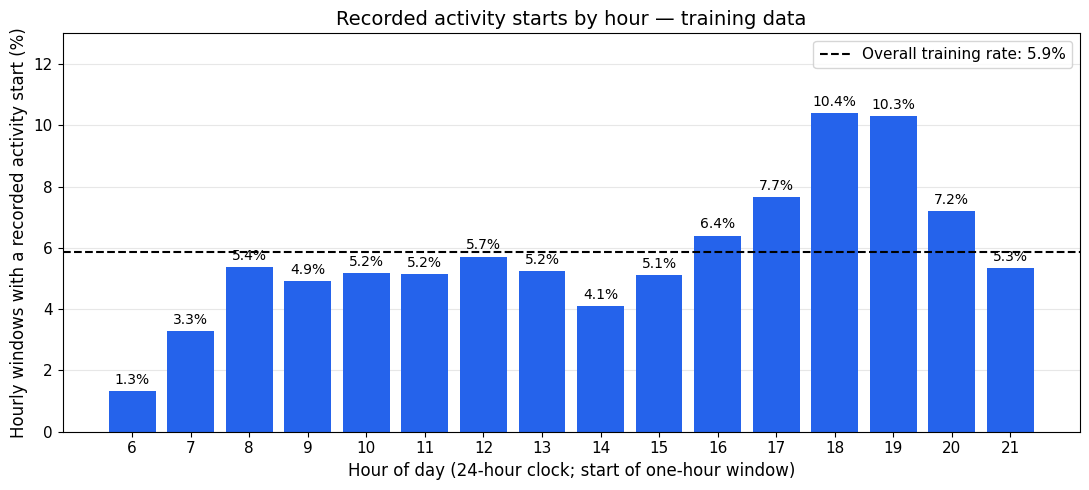

In [ ]:
import matplotlib.pyplot as plt

# Calculate the observed activity-start rate at each hour
hour_summary = train_data.groupby("hour")["activity_start"].agg(
    hourly_windows="count",
    activity_starts="sum",
    start_fraction="mean"
)

hour_summary["start_percent"] = (
    hour_summary["start_fraction"] * 100
)

overall_rate = train_data["activity_start"].mean() * 100

fig_hour, ax_hour = plt.subplots(figsize=(11, 5))

bars = ax_hour.bar(
    hour_summary.index,
    hour_summary["start_percent"],
    color="#2563EB"
)

ax_hour.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in hour_summary["start_percent"]],
    padding=3,
    fontsize=10
)

ax_hour.axhline(
    overall_rate,
    color="black",
    linestyle="--",
    label=f"Overall training rate: {overall_rate:.1f}%"
)

ax_hour.set_title(
    "Recorded activity starts by hour — training data", fontsize=14
)
ax_hour.set_xlabel(
    "Hour of day (24-hour clock; start of one-hour window)", fontsize=12
)
ax_hour.set_ylabel(
    "Hourly windows with a recorded activity start (%)", fontsize=12
)

ax_hour.set_xticks(range(6, 22))
ax_hour.set_ylim(
    0, max(hour_summary["start_percent"].max(), overall_rate) * 1.25
)
ax_hour.tick_params(labelsize=11)
ax_hour.grid(axis="y", alpha=0.3)
ax_hour.set_axisbelow(True)
ax_hour.legend(fontsize=11)

fig_hour.tight_layout()
fig_hour.savefig(
    "/content/Feature_hour_vs_start.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Training rows plotted: 31481
Rows with missing history left out: 6897


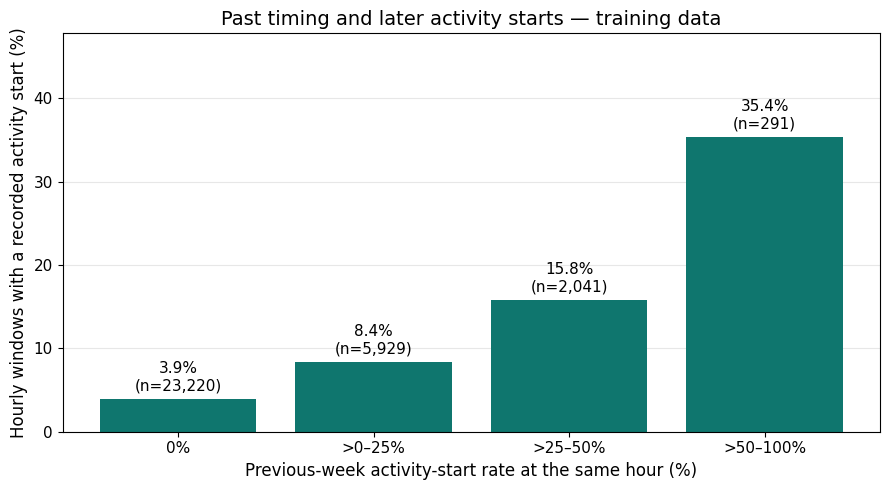

In [ ]:
# Use training rows where the historical rate is available
history_plot = train_data.dropna(
    subset=["past_hour_start_rate"]
).copy()

history_plot["history_group"] = pd.cut(
    history_plot["past_hour_start_rate"],
    bins=[-0.001, 0, 0.25, 0.50, 1.0],
    labels=["0%", ">0–25%", ">25–50%", ">50–100%"]
)

history_summary = history_plot.groupby(
    "history_group", observed=True
)["activity_start"].agg(
    hourly_windows="count",
    activity_starts="sum",
    start_fraction="mean"
)

history_summary["start_percent"] = (
    history_summary["start_fraction"] * 100
)

fig_history, ax_history = plt.subplots(figsize=(9, 5))

bars = ax_history.bar(
    history_summary.index.astype(str),
    history_summary["start_percent"],
    color="#0F766E"
)

ax_history.bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={count:,})"
        for rate, count in zip(
            history_summary["start_percent"],
            history_summary["hourly_windows"]
        )
    ],
    padding=4,
    fontsize=11
)

ax_history.set_title(
    "Past timing and later activity starts — training data", fontsize=14
)
ax_history.set_xlabel(
    "Previous-week activity-start rate at the same hour (%)", fontsize=12
)
ax_history.set_ylabel(
    "Hourly windows with a recorded activity start (%)", fontsize=12
)

ax_history.set_ylim(
    0, history_summary["start_percent"].max() * 1.35
)
ax_history.tick_params(labelsize=11)
ax_history.grid(axis="y", alpha=0.3)
ax_history.set_axisbelow(True)

fig_history.tight_layout()
fig_history.savefig(
    "/content/Feature_history_vs_start.png",
    dpi=300,
    bbox_inches="tight"
)

print("Training rows plotted:", len(history_plot))
print("Rows with missing history left out:", len(train_data) - len(history_plot))
plt.show()

Training rows plotted: 32630
Rows with missing step averages left out: 5748


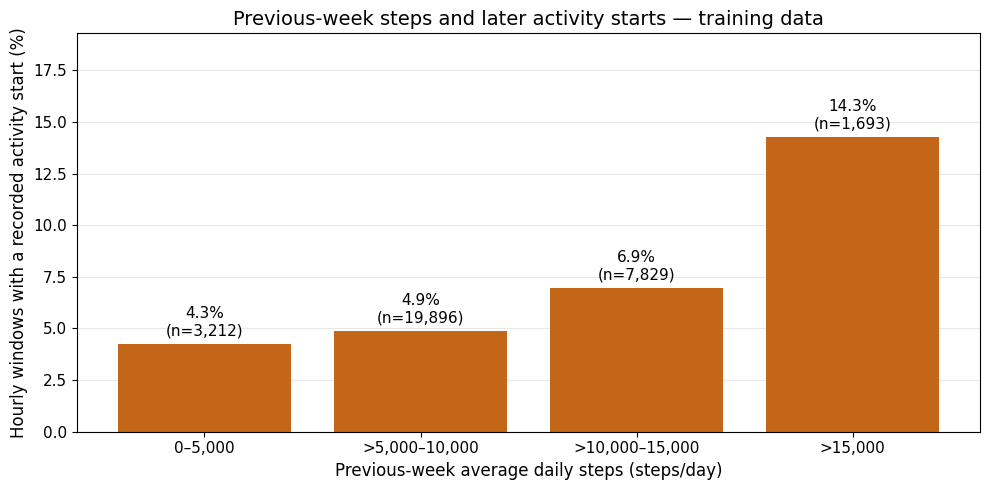

In [ ]:
# Keep training rows with an available previous-week step average
steps_plot = train_data.dropna(
    subset=["past_mean_steps"]
).copy()

steps_plot["step_group"] = pd.cut(
    steps_plot["past_mean_steps"],
    bins=[-0.001, 5000, 10000, 15000, float("inf")],
    labels=[
        "0–5,000",
        ">5,000–10,000",
        ">10,000–15,000",
        ">15,000"
    ]
)

steps_summary = steps_plot.groupby(
    "step_group", observed=True
)["activity_start"].agg(
    hourly_windows="count",
    activity_starts="sum",
    start_fraction="mean"
)

steps_summary["start_percent"] = (
    steps_summary["start_fraction"] * 100
)

fig_steps_feature, ax_steps_feature = plt.subplots(figsize=(10, 5))

bars = ax_steps_feature.bar(
    steps_summary.index.astype(str),
    steps_summary["start_percent"],
    color="#C46618"
)

ax_steps_feature.bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={count:,})"
        for rate, count in zip(
            steps_summary["start_percent"],
            steps_summary["hourly_windows"]
        )
    ],
    padding=4,
    fontsize=11
)

ax_steps_feature.set_title(
    "Previous-week steps and later activity starts — training data",
    fontsize=14
)
ax_steps_feature.set_xlabel(
    "Previous-week average daily steps (steps/day)", fontsize=12
)
ax_steps_feature.set_ylabel(
    "Hourly windows with a recorded activity start (%)", fontsize=12
)

ax_steps_feature.set_ylim(
    0, steps_summary["start_percent"].max() * 1.35
)
ax_steps_feature.tick_params(labelsize=11)
ax_steps_feature.grid(axis="y", alpha=0.3)
ax_steps_feature.set_axisbelow(True)

fig_steps_feature.tight_layout()
fig_steps_feature.savefig(
    "/content/Feature_steps_vs_start.png",
    dpi=300,
    bbox_inches="tight"
)

print("Training rows plotted:", len(steps_plot))
print("Rows with missing step averages left out:", len(train_data) - len(steps_plot))
plt.show()

,Feature,MI,Missing_only_MI,Missing_percent
0,Past start rate at the same hour,0.00948,0.00000,18.0
1,Hour of day,0.00449,0.00000,0.0
2,Previous-week mean steps,0.00301,0.00002,15.0
3,Previous-week mean resting heart rate,0.00154,0.00002,16.2
4,Day of week,0.00089,0.00000,0.0
5,Previous-week mean heart rate,0.00077,0.00001,15.2
6,Previous-week mean HRV,0.00030,0.00006,49.3
7,Previous-week mean sleep duration,0.00023,0.00000,28.2


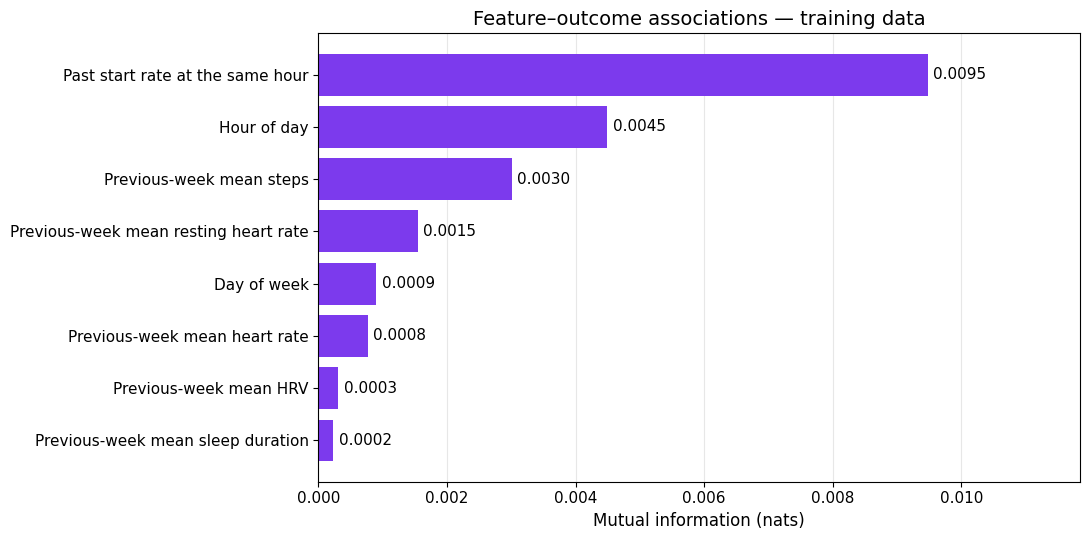

In [ ]:
from sklearn.metrics import mutual_info_score

feature_labels = {
    "hour": "Hour of day",
    "weekday": "Day of week",
    "past_hour_start_rate": "Past start rate at the same hour",
    "past_mean_steps": "Previous-week mean steps",
    "past_mean_hr": "Previous-week mean heart rate",
    "past_mean_resting_hr": "Previous-week mean resting heart rate",
    "past_mean_hrv": "Previous-week mean HRV",
    "past_mean_sleep_hours": "Previous-week mean sleep duration"
}

outcome = train_data["activity_start"]
mi_records = []

for column, label in feature_labels.items():
    values = train_data[column]

    if column in ["hour", "weekday"]:
        encoded = values

    elif column == "past_hour_start_rate":
        # Same groups as the history graph
        encoded = pd.cut(
            values,
            bins=[-0.001, 0, 0.25, 0.50, 1],
            labels=False
        )

    elif column == "past_mean_steps":
        # Same groups as the steps graph
        encoded = pd.cut(
            values,
            bins=[-0.001, 5000, 10000, 15000, float("inf")],
            labels=False
        )

    else:
        # Divide other measurements into up to four
        # roughly equal-sized groups using training data
        encoded = pd.qcut(
            values, q=4, labels=False, duplicates="drop"
        )

    # -1 represents a missing category, not a measured value
    encoded = encoded.fillna(-1).astype(int)

    mi_records.append({
        "Column": column,
        "Feature": label,
        "MI": mutual_info_score(encoded, outcome),
        "Missing_only_MI": mutual_info_score(
            values.isna().astype(int), outcome
        ),
        "Missing_percent": values.isna().mean() * 100
    })

mi_results = (
    pd.DataFrame(mi_records)
    .sort_values("MI", ascending=False)
    .reset_index(drop=True)
)

display(
    mi_results.drop(columns="Column").round({
        "MI": 5,
        "Missing_only_MI": 5,
        "Missing_percent": 1
    })
)

# Plot the ranking
plot_results = mi_results.sort_values("MI")

fig_mi, ax_mi = plt.subplots(figsize=(11, 5.5))

bars = ax_mi.barh(
    plot_results["Feature"],
    plot_results["MI"],
    color="#7C3AED"
)

ax_mi.bar_label(bars, fmt="%.4f", padding=4, fontsize=11)
ax_mi.set_xlabel("Mutual information (nats)", fontsize=12)
ax_mi.set_title(
    "Feature–outcome associations — training data", fontsize=14
)
ax_mi.set_xlim(0, mi_results["MI"].max() * 1.25)
ax_mi.tick_params(labelsize=11)
ax_mi.grid(axis="x", alpha=0.3)
ax_mi.set_axisbelow(True)

fig_mi.tight_layout()
fig_mi.savefig(
    "/content/Feature_mutual_information.png",
    dpi=300,
    bbox_inches="tight"
)
mi_results.to_csv(
    "/content/Feature_mutual_information.csv", index=False
)
plt.show()

In [ ]:
import zipfile
from google.colab import files

feature_data.to_csv(
    "/content/Body_Copilot_features.csv", index=False
)

filenames = [
    "HRV_before_after.png",
    "Sleep_before_after.png",
    "Steps_previous_week_mean.png",
    "Feature_hour_vs_start.png",
    "Feature_history_vs_start.png",
    "Feature_steps_vs_start.png",
    "Feature_mutual_information.png",
    "Feature_mutual_information.csv",
    "Body_Copilot_features.csv"
]

zip_path = "/content/Body_Copilot_Assignment2_results.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for filename in filenames:
        archive.write("/content/" + filename, arcname=filename)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Read the two data files
daily = pd.read_csv(
    "daily_fitbit_sema_df_unprocessed.csv", low_memory=False
)
hourly = pd.read_csv(
    "hourly_fitbit_sema_df_unprocessed.csv", low_memory=False
)

# Make the dates usable for calculations
daily["date"] = pd.to_datetime(daily["date"])
hourly["date"] = pd.to_datetime(hourly["date"])

print("Daily rows:", len(daily))
print("Hourly rows:", len(hourly))
print("Participants:", hourly["id"].nunique())

# Preview the columns we will use
display(daily[
    ["id", "date", "steps", "resting_hr", "rmssd", "minutesAsleep"]
].head())

display(hourly[
    ["id", "date", "hour", "activityType", "bpm", "steps"]
].head())

FileNotFoundError: [Errno 2] No such file or directory: 'daily_fitbit_sema_df_unprocessed.csv'

In [ ]:
# Keep one record per person, date, and hour
hours = hourly.drop_duplicates(
    subset=["id", "date", "hour"]
).copy()

# Include 6 a.m. through the 9–10 p.m. window
hours = hours[hours["hour"].between(6, 21)].copy()

# Identify recorded starts and available measurements
has_start = hours["activityType"].notna()
has_measurements = hours["bpm"].notna() & hours["steps"].notna()

# Exclude uncertain hours without an activity start
hours = hours[has_start | has_measurements].copy()

# Create the outcome column
hours["label"] = hours["activityType"].notna().astype(int)

print("Hours without a recorded start:", (hours["label"] == 0).sum())
print("Hours with a recorded start:", (hours["label"] == 1).sum())
print("Percentage with a start:", round(hours["label"].mean() * 100, 2))

display(hours[
    ["id", "date", "hour", "activityType", "label"]
].head(10))

Hours without a recorded start: 60875
Hours with a recorded start: 3591
Percentage with a start: 5.57


,id,date,hour,activityType,label
6,621e2e8e67b776a24055b564,2021-05-24,6.0,NaN,0
7,621e2e8e67b776a24055b564,2021-05-24,7.0,NaN,0
8,621e2e8e67b776a24055b564,2021-05-24,8.0,NaN,0
9,621e2e8e67b776a24055b564,2021-05-24,9.0,NaN,0
10,621e2e8e67b776a24055b564,2021-05-24,10.0,['Walk'],1
11,621e2e8e67b776a24055b564,2021-05-24,11.0,NaN,0
12,621e2e8e67b776a24055b564,2021-05-24,12.0,NaN,0
13,621e2e8e67b776a24055b564,2021-05-24,13.0,NaN,0
14,621e2e8e67b776a24055b564,2021-05-24,14.0,NaN,0
15,621e2e8e67b776a24055b564,2021-05-24,15.0,NaN,0


In [ ]:
# Keep the outcome and identifying information
work = hours[["id", "date", "hour", "label"]].copy()

# Find the Sunday when each weekly plan would be created
work["plan_date"] = work["date"] - pd.to_timedelta(
    (work["date"].dt.dayofweek + 1) % 7, unit="D"
)

blocks = []

for (person, plan_date), week in work.groupby(["id", "plan_date"]):
    start = plan_date - pd.Timedelta(days=7)

    # Only use daily records from BEFORE the weekly plan
    past = daily[
        (daily["id"] == person)
        & (daily["date"] >= start)
        & (daily["date"] < plan_date)
    ]

    # For this exercise, require at least 3 days with step data
    if past["steps"].notna().sum() < 3:
        continue

    past_hours = hours[
        (hours["id"] == person)
        & (hours["date"] >= start)
        & (hours["date"] < plan_date)
    ]

    week = week.copy()

    # Extract calendar and wearable features
    week["day_of_week"] = week["date"].dt.dayofweek
    week["past_mean_steps"] = past["steps"].mean()
    week["past_mean_hr"] = past["bpm"].mean()
    week["past_mean_resting_hr"] = past["resting_hr"].mean()
    week["past_mean_hrv"] = past["rmssd"].mean()
    week["past_mean_sleep_hours"] = past["minutesAsleep"].mean() / 60

    # Fraction of available past records with a start at each hour
    rates = past_hours.groupby("hour")["label"].mean()
    week["past_hour_start_rate"] = week["hour"].map(rates)

    blocks.append(week)

features = pd.concat(blocks, ignore_index=True)

feature_names = [
    "hour",
    "day_of_week",
    "past_hour_start_rate",
    "past_mean_steps",
    "past_mean_hr",
    "past_mean_resting_hr",
    "past_mean_hrv",
    "past_mean_sleep_hours"
]

print("Rows:", len(features))
print("Features:", len(feature_names))
display(features[feature_names + ["label"]].head())

Rows: 57550
Features: 8


,hour,day_of_week,past_hour_start_rate,past_mean_steps,past_mean_hr,past_mean_resting_hr,past_mean_hrv,past_mean_sleep_hours,label
0,6.0,6,0.0,12383.833333,73.998286,62.2441,101.300333,8.061111,0
1,7.0,6,0.0,12383.833333,73.998286,62.2441,101.300333,8.061111,0
2,8.0,6,0.0,12383.833333,73.998286,62.2441,101.300333,8.061111,0
3,9.0,6,0.5,12383.833333,73.998286,62.2441,101.300333,8.061111,0
4,10.0,6,0.5,12383.833333,73.998286,62.2441,101.300333,8.061111,0


,Feature,MI_score
2,past_hour_start_rate,0.008164
0,hour,0.004440
3,past_mean_steps,0.002579
5,past_mean_resting_hr,0.002187
6,past_mean_hrv,0.000932
4,past_mean_hr,0.000794
7,past_mean_sleep_hours,0.000686
1,day_of_week,0.000611


Selected features: ['past_hour_start_rate', 'hour', 'past_mean_steps', 'past_mean_resting_hr', 'past_mean_hrv']


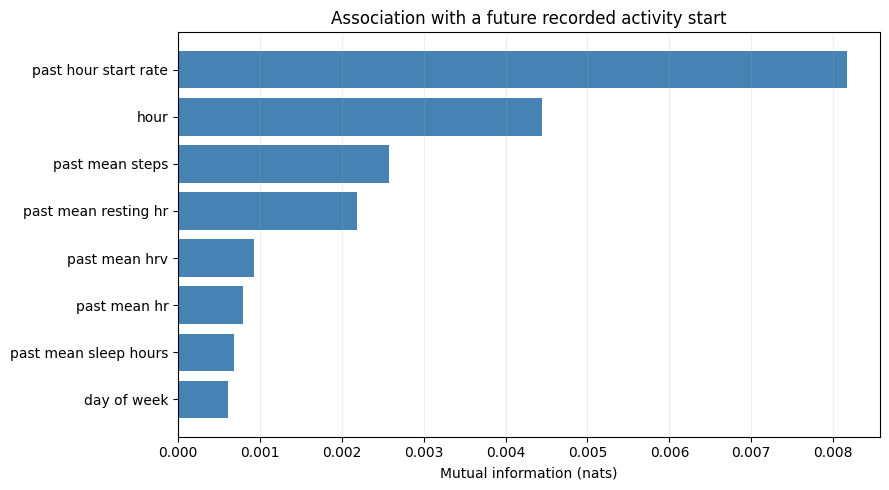

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

# Use each person's earlier 70% of weeks for feature selection
weeks = (
    features[["id", "plan_date"]]
    .drop_duplicates()
    .sort_values(["id", "plan_date"])
)

weeks["week_number"] = weeks.groupby("id").cumcount()
weeks["number_of_weeks"] = (
    weeks.groupby("id")["plan_date"].transform("size")
)

train_weeks = weeks[
    weeks["week_number"] < np.floor(weeks["number_of_weeks"] * 0.7)
]

training = features.merge(
    train_weeks[["id", "plan_date"]],
    on=["id", "plan_date"]
)

X = training[feature_names].copy()
y = training["label"]

# Group continuous measurements into up to four levels.
# Keep hour and weekday as their original categories.
for name in feature_names:
    if name not in ["hour", "day_of_week"]:
        X[name] = pd.qcut(
            X[name], q=4, labels=False, duplicates="drop"
        )

# Treat missing measurements as a separate category
X = X.fillna(-1).astype(int)

scores = mutual_info_classif(
    X, y, discrete_features=True, random_state=42
)

ranking = pd.DataFrame({
    "Feature": feature_names,
    "MI_score": scores
}).sort_values("MI_score", ascending=False)

display(ranking.round(6))

# Select five candidates for the class demonstration
selected_features = ranking.head(5)["Feature"].tolist()
print("Selected features:", selected_features)

# Create the ranking chart
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    ranking["Feature"].str.replace("_", " "),
    ranking["MI_score"],
    color="steelblue"
)
ax.invert_yaxis()
ax.set_xlabel("Mutual information (nats)")
ax.set_title("Association with a future recorded activity start")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()